# Étape 3 : deep learning contre machine learning classique


**Objectif :** même tâche (5 paramètres → 88 volatilités), mêmes données et mêmes métriques pour des modèles
classiques, comparés au réseau final. Puis courbe d'apprentissage selon la taille du jeu d'entraînement.

**Configuration :** imports, `configs/base.yaml`, et `MACHINE_ID` (0, 1, 2 ou 3 selon la machine) : chaque machine ne calcule que ses modèles.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

from heston_nn.config import load_config, load_yaml, repo_path
from heston_nn.data.split import split_dataset
from heston_nn.models.classical import (error_bp,
                                        fit_gaussian_process, tune_on_validation)
from heston_nn.timing.benchmark import measure_time

cfg = load_config("configs/base.yaml")

MACHINE_ID = 2
MODELS_BY_MACHINE = {
    2: ["lightgbm","gaussian_process","ridge_poly","random_forest","knn"],
}
MODELS_TO_RUN = MODELS_BY_MACHINE[MACHINE_ID]

**Données :** chargement de `data/surfaces.npz`, découpage commun 80 / 10 / 10, et lecture de `configs/etape3/classical.yaml`.

Les surfaces avec des NaN sont retirées de l'entraînement et de la validation. Sur le test on les garde : l'erreur est calculée sur les points valides seulement.

In [2]:
data = np.load(repo_path("data", "surfaces.npz"))
X, Y = data["X"], data["Y"]

split = split_dataset(X, Y, cfg)
X_train, Y_train = split["train"]
X_val, Y_val = split["val"]
X_test, Y_test = split["test"]

# on enlève les surfaces avec au moins un NaN (entraînement et validation)
keep_train = ~np.isnan(Y_train).any(axis=1)
keep_val = ~np.isnan(Y_val).any(axis=1)
X_train, Y_train = X_train[keep_train], Y_train[keep_train]
X_val, Y_val = X_val[keep_val], Y_val[keep_val]
print("train :", len(X_train), "| val :", len(X_val), "| test :", len(X_test))

# on standardise les 5 paramètres (moyenne et écart-type de l'entraînement seulement)
x_scaler = StandardScaler()
X_train = x_scaler.fit_transform(X_train)
X_val = x_scaler.transform(X_val)
X_test = x_scaler.transform(X_test)

classical_cfg = load_yaml(repo_path("configs", "etape3", "classical.yaml"))
results_dir = repo_path("results", "etape3")
results_dir.mkdir(parents=True, exist_ok=True)

train : 17569 | val : 2161 | test : 5000


## 1. Modèles classiques
Pour chaque modèle : réglage sur la validation, erreur sur le test (moyenne et max, en pb) et temps de réponse pour une surface. Les résultats sont écrits dans `results/etape3/`.

In [ ]:
for name in MODELS_TO_RUN:
    print(f"=== {name} ===")
    start = time.time()

    if name == "gaussian_process":
        n_max = classical_cfg["models"][name]["max_train_samples"]
        model = fit_gaussian_process(X_train, Y_train, n_max)
        best_params = {"max_train_samples": n_max}
    else:
        grid = classical_cfg["models"][name]
        model, best_params = tune_on_validation(name, grid, (X_train, Y_train), (X_val, Y_val))
    train_seconds = time.time() - start

    val_mean, _ = error_bp(Y_val, model.predict(X_val))
    test_mean, test_max = error_bp(Y_test, model.predict(X_test))

    # Temps de réponse pour UNE surface : on coupe le parallélisme (n_jobs=1).
    # Avec n_jobs=-1, chaque predict envoie les modèles à des processus séparés : pour une seule surface,
    # ce transfert coûte bien plus que la prédiction elle-même (LightGBM : 88 modèles copiés à chaque appel).
    if "n_jobs" in model.get_params():
        model.set_params(n_jobs=1)
    response_s = measure_time(model.predict, X_test[:1])

    result = {"model": name, "best_params": best_params,
              "val_mean_bp": val_mean, "test_mean_bp": test_mean, "test_max_bp": test_max,
              "response_s": response_s, "train_seconds": train_seconds, "n_train": len(X_train)}
    with open(results_dir / f"classical_{name}.json", "w") as f:
        json.dump(result, f, indent=2)
    print(f"meilleurs paramètres : {best_params}")
    print(f"test : {test_mean:.1f} pb en moyenne, {test_max:.0f} pb au max, {1e3 * response_s:.2f} ms par surface")

Tableau des modèles classiques (tous ceux déjà calculés, par toutes les machines) :

In [3]:
rows = []
for path in sorted(results_dir.glob("classical_*.json")):
    with open(path) as f:
        rows.append(json.load(f))
table = pd.DataFrame(rows).set_index("model")
table[["val_mean_bp", "test_mean_bp", "test_max_bp", "response_s", "train_seconds"]].round(4)

,val_mean_bp,test_mean_bp,test_max_bp,response_s,train_seconds
model,,,,,
gaussian_process,0.9366,7.0876,515.4266,0.0081,56.2719
knn,47.1404,161.7596,2213.8314,0.0022,1.8661
lightgbm,15.8701,59.1280,1610.3066,0.0864,111.8063
random_forest,43.2415,109.5856,2186.2528,0.0180,85.6684
ridge_poly,8.0767,17.4488,880.9794,0.0003,0.6162


## 2. Comparaison avec le réseau final

On reprend la configuration du réseau final (`results/reseau_final/`) et on le ré-entraîne sur les mêmes données que
les modèles classiques, c'est-à-dire sans les surfaces qui contiennent des NaN, avec les graines 0, 1 et 2 de
l'étape 2. On le compare aussi au réseau final tel quel, qui a appris sur toutes les surfaces grâce à la perte masquée.

Si un entraînement a déjà été fait, la cellule relit son résultat au lieu de le recalculer.

In [4]:
import keras

from heston_nn.experiments import load_result
from heston_nn.models.classical import build_classical_model
from heston_nn.models.mlp import load_model, make_predict_fn
from heston_nn.timing.benchmark import load_fourier_time, passes_threshold, speed_gain
from heston_nn.training.train import run_experiment

# Le réseau final de l'étape 2 et sa configuration
final_model, final_x_scaler, final_y_scaler, final_cfg = load_model(repo_path("results", "reseau_final"))
print("réseau final :", final_cfg["model"], final_cfg["train"])

# Mêmes données que le ML ; le réseau apprend des volatilités normalisées (comme aux étapes 1 et 2)
y_scaler = StandardScaler().fit(Y_train)
scaled = {"train": (X_train, y_scaler.transform(Y_train)),
          "val": (X_val, y_scaler.transform(Y_val)),
          "test": (X_test, y_scaler.transform(Y_test))}
SEEDS = [0, 1, 2]


def train_network(name, data, seed):
    """Entraîne le réseau final sur data (ou relit le résultat s'il existe) ; renvoie ses métriques."""
    run_dir = repo_path("results", name, f"seed_{seed}")
    if not (run_dir / "metrics.json").exists():
        cfg_run = {"name": name, "model": final_cfg["model"], "train": final_cfg["train"]}
        run_experiment(cfg_run, seed, (data, x_scaler, y_scaler))
    return load_result(run_dir)["metrics"]


runs = pd.DataFrame([train_network("etape3_reseau_final_sans_nan", scaled, seed) for seed in SEEDS])
runs[["seed", "val_mean_bp", "test_mean_bp", "test_max_bp", "best_epoch"]].round(2)

réseau final : {'hidden_layers': 2, 'width': 128, 'activation': 'gelu', 'init': 'he'} {'epochs': 200, 'batch_size': 32, 'optimizer': 'adam', 'lr': 0.001, 'loss': 'mse'}


,seed,val_mean_bp,test_mean_bp,test_max_bp,best_epoch
0,0,2.65,10.61,542.32,151
1,1,2.82,9.75,484.81,200
2,2,3.70,11.79,495.41,200


### Erreurs sur le test

On compare les deux versions du réseau aux deux meilleurs modèles classiques, ré-entraînés avec leurs meilleurs
hyperparamètres (le GP prend environ 1 min). L'erreur est séparée entre les surfaces de test complètes et celles qui
ont au moins un NaN. Ces dernières ressemblent aux surfaces retirées de l'entraînement : les modèles entraînés sans
NaN n'en ont jamais vu.

In [5]:
X_test_raw = split["test"][0]                          # paramètres de test non normalisés
has_nan = np.isnan(Y_test).any(axis=1)                 # surfaces de test avec au moins un NaN


def test_errors(Y_pred):
    """Erreurs de test en pb : moyenne, max, et moyenne sur les surfaces complètes / avec NaN."""
    mean, worst = error_bp(Y_test, Y_pred)
    return {"test moyen": mean, "test max": worst,
            "surfaces complètes": error_bp(Y_test[~has_nan], Y_pred[~has_nan])[0],
            "surfaces avec NaN": error_bp(Y_test[has_nan], Y_pred[has_nan])[0]}


def network_predict(model, x_sc, y_sc):
    """Volatilités prédites par un réseau sur tout le test."""
    return y_sc.inverse_transform(np.asarray(model(x_sc.transform(X_test_raw), training=False)))


# Réseau sans NaN : moyenne des erreurs des 3 graines
same_data = []
for seed in SEEDS:
    model = keras.models.load_model(repo_path("results", "etape3_reseau_final_sans_nan", f"seed_{seed}", "model.keras"),
                                    compile=False)
    same_data.append(test_errors(network_predict(model, x_scaler, y_scaler)))

# Les deux meilleurs modèles classiques
ridge = build_classical_model("ridge_poly", table.loc["ridge_poly", "best_params"]).fit(X_train, Y_train)
gp = fit_gaussian_process(X_train, Y_train, classical_cfg["models"]["gaussian_process"]["max_train_samples"])

errors = pd.DataFrame({
    "réseau, toutes surfaces (40 000)": test_errors(network_predict(final_model, final_x_scaler, final_y_scaler)),
    "réseau, sans NaN (17 569)": pd.DataFrame(same_data).mean(),
    "gaussian_process (5 000)": test_errors(gp.predict(X_test)),
    "ridge_poly (17 569)": test_errors(ridge.predict(X_test)),
}).T
errors.to_csv(results_dir / "erreurs_test.csv")
errors.round(2)

C:\Users\nou-z\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\gaussian_process\kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


,test moyen,test max,surfaces complètes,surfaces avec NaN
"réseau, toutes surfaces (40 000)",2.58,92.87,2.45,2.69
"réseau, sans NaN (17 569)",10.72,507.51,3.00,16.96
gaussian_process (5 000),7.09,515.43,0.93,12.06
ridge_poly (17 569),17.45,880.98,7.79,25.25


### Temps de réponse pour une surface

Le `predict` de scikit-learn a des frais fixes bien plus longs que le calcul lui-même : le GP y prend 8 ms, plus que
Fourier (2,3 ms en Julia). Comme le réseau est chronométré en numpy pur (`make_predict_fn`), on réécrit aussi la ridge et le GP en
numpy, et la cellule vérifie que leurs prédictions n'ont pas changé.

In [6]:
# Ridge en numpy : monômes de degré ≤ 4, puis produit matriciel
powers, weights, bias = ridge[0].powers_, ridge[1].coef_.T, ridge[1].intercept_


def ridge_numpy(x):
    return np.prod(x ** powers, axis=1) @ weights + bias


# GP en numpy : noyau RBF entre le point et les points d'entraînement, puis combinaison par alpha
constant, length = gp.kernel_.k1.k1.constant_value, gp.kernel_.k1.k2.length_scale
gp_points = gp.X_train_ / length


def gp_numpy(x):
    kernel = constant * np.exp(-0.5 * ((x / length - gp_points) ** 2).sum(axis=1))
    return (kernel @ gp.alpha_) * gp._y_train_std + gp._y_train_mean


x = X_test[0]                                          # un jeu de paramètres (déjà normalisé)
assert np.allclose(ridge_numpy(x), ridge.predict(X_test[:1])[0])
assert np.allclose(gp_numpy(x), gp.predict(X_test[:1])[0])

t_fourier = load_fourier_time()                        # Julia, une surface, 1 thread
times = {
    "réseau": measure_time(make_predict_fn(final_model, final_x_scaler, final_y_scaler), X_test_raw[0]),
    "gaussian_process": measure_time(gp_numpy, x),
    "ridge_poly": measure_time(ridge_numpy, x),
}
timing = pd.DataFrame([{"modèle": name, "temps (ms)": 1e3 * t, "gain vs Fourier": speed_gain(t_fourier, t),
                        "assez rapide": passes_threshold(speed_gain(t_fourier, t), cfg["speed_threshold"])}
                       for name, t in times.items()]).set_index("modèle")
print(f"Fourier : {1e3 * t_fourier:.2f} ms par surface ; seuil : gain ≥ {cfg['speed_threshold']}")
timing.round(3)

Fourier : 2.29 ms par surface ; seuil : gain ≥ 10


,temps (ms),gain vs Fourier,assez rapide
modèle,,,
réseau,0.032,72.240,True
gaussian_process,0.175,13.075,True
ridge_poly,0.011,199.131,True


## 3. Courbe d'apprentissage

On regarde comment l'erreur évolue avec la taille du jeu d'entraînement. Le réseau final, le GP et la ridge sont
entraînés sur 1 000, 5 000 et 10 000 surfaces, puis sur les 17 569 surfaces sans NaN (`data.split.subsample`). Les
graines sont 0, 1 et 2, et la graine choisit aussi le sous-échantillon. La validation et le test sont ceux de la
section 2.

Le GP reste limité à 5 000 surfaces (`max_train_samples`). Au-delà, il prend les 5 000 premières du sous-échantillon,
donc sa courbe ne peut plus descendre. La première exécution dure environ 15 minutes ; ensuite, la cellule relit
`results/etape3/courbe_apprentissage.csv`.

In [7]:
from heston_nn.data.split import subsample

n_full = len(X_train)
sizes = [n_full if size == "full" else size for size in classical_cfg["learning_curve"]["train_sizes"]]
gp_max = classical_cfg["models"]["gaussian_process"]["max_train_samples"]
curve_path = results_dir / "courbe_apprentissage.csv"

if curve_path.exists():
    curve = pd.read_csv(curve_path)
else:
    rows = []
    for size in sizes:
        for seed in SEEDS:
            print(f"taille {size}, graine {seed}")
            X_sub, Y_sub = subsample(X_train, Y_train, size, seed)
            data = {"train": (X_sub, y_scaler.transform(Y_sub)), "val": scaled["val"], "test": scaled["test"]}
            # sur le jeu complet, c'est exactement l'entraînement de la section 2 : on le relit
            name = "etape3_reseau_final_sans_nan" if size == n_full else f"etape3_courbe_{size}"
            network = train_network(name, data, seed)
            ridge_sub = build_classical_model("ridge_poly", table.loc["ridge_poly", "best_params"]).fit(X_sub, Y_sub)
            gp_sub = fit_gaussian_process(X_sub, Y_sub, gp_max)
            rows.append({"taille": size, "graine": seed,
                         "réseau": network["test_mean_bp"],
                         "gaussian_process": error_bp(Y_test, gp_sub.predict(X_test))[0],
                         "ridge_poly": error_bp(Y_test, ridge_sub.predict(X_test))[0]})
    curve = pd.DataFrame(rows)
    curve.to_csv(curve_path, index=False)

curve_summary = curve.groupby("taille")[["réseau", "gaussian_process", "ridge_poly"]].agg(["mean", "std"])
curve_summary.round(2)

réseau       gaussian_process       ridge_poly      
         mean   std             mean   std       mean   std
taille                                                     
1000    43.85  2.96            11.48  0.41      30.83  3.10
5000    17.65  2.00             6.89  0.19      18.29  0.41
10000   12.93  0.95             7.21  0.29      17.61  0.12
17569   10.72  1.02             7.09  0.00      17.45  0.00

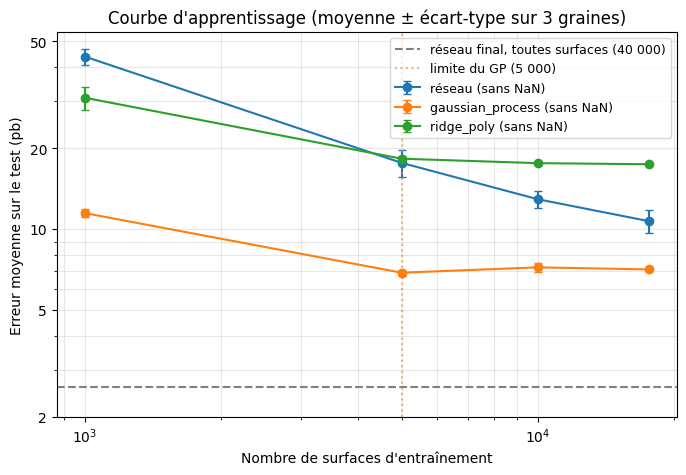

In [8]:
fig, axis = plt.subplots(figsize=(8, 5))
for name in ["réseau", "gaussian_process", "ridge_poly"]:
    axis.errorbar(curve_summary.index, curve_summary[(name, "mean")], yerr=curve_summary[(name, "std")],
                  marker="o", capsize=3, label=f"{name} (sans NaN)")
axis.axhline(errors.loc["réseau, toutes surfaces (40 000)", "test moyen"], color="gray", linestyle="--",
             label="réseau final, toutes surfaces (40 000)")
axis.axvline(gp_max, color="tab:orange", linestyle=":", alpha=0.6, label="limite du GP (5 000)")
axis.set_xscale("log")
axis.set_yscale("log")
axis.set_yticks([2, 5, 10, 20, 50], ["2", "5", "10", "20", "50"])
axis.set_xlabel("Nombre de surfaces d'entraînement")
axis.set_ylabel("Erreur moyenne sur le test (pb)")
axis.set_title("Courbe d'apprentissage (moyenne ± écart-type sur 3 graines)")
axis.grid(True, which="both", alpha=0.3)
axis.legend(loc="upper right", fontsize=9)
plt.savefig(repo_path("results", "figures", "etape3_courbe_apprentissage.png"), dpi=150, bbox_inches="tight")
plt.show()

## Conclusion

À données égales, le processus gaussien est plus précis que le réseau. Sur les mêmes surfaces sans NaN, le GP fait
7,1 pb sur le test et le réseau final 10,7 ± 1,0 pb ; sur les surfaces complètes, c'est 0,9 pb contre 3,0 pb. Le
réseau fait en revanche mieux que tous les autres modèles classiques : ridge 17,4 pb, LightGBM 59 pb, forêt aléatoire
110 pb, k plus proches voisins 162 pb.

Côté vitesse, on chronomètre tout en numpy pur, face à Fourier en Julia (2,3 ms par surface). La ridge va environ 200
fois plus vite que Fourier et le réseau environ 70 fois. Le GP passe le seuil (gain d'au moins 10), mais de peu, avec
un gain de 13. Sur une exécution faite pendant que la machine travaillait à autre chose, il est descendu juste sous 10.
Le réseau va 5 à 6 fois plus vite que le GP, parce que le GP compare chaque nouveau jeu de paramètres aux 5 000 surfaces
d'entraînement, alors que le coût du réseau ne dépend pas de la taille du jeu.

La courbe d'apprentissage explique la différence. Avec 1 000 surfaces, le GP fait 11,5 pb et le réseau 44 pb. La
ridge plafonne vers 17,5 pb dès 5 000 surfaces, parce que le modèle est trop simple. Le GP ne peut pas utiliser plus
de 5 000 surfaces : son entraînement coûte n³ et demanderait une matrice n × n de 12,8 Go pour 40 000 surfaces. Le
réseau est le seul dont l'erreur baisse encore à la taille maximale (44, puis 18, 13 et 11 pb).

Avec toutes les données, le réseau passe devant. Les modèles de scikit-learn ont besoin de sorties complètes, et il a
fallu retirer 56 % des surfaces pour eux. Avec la perte masquée, le réseau apprend sur les 40 000 surfaces en ignorant
seulement les points sans prix fiable. Il fait alors 2,6 pb sur le test, 2,7 fois mieux que le GP. Son erreur est
presque la même sur les surfaces complètes (2,4 pb) et sur les autres (2,7 pb), et son erreur maximale est de 93 pb,
alors qu'elle dépasse 500 pb pour tous les autres modèles.

Sur un petit jeu complet, le GP reste donc meilleur qu'un réseau. Ce que le deep learning apporte ici, c'est de
continuer à progresser quand on ajoute des données, et de pouvoir adapter la perte aux données.

### Limites

- Les grilles d'hyperparamètres des modèles classiques sont petites, alors que le réseau a été réglé en détail aux
  étapes 1 et 2.
- On aurait pu compléter les NaN par imputation pour garder toutes les surfaces côté ML. Ce n'est pas testé.
- Le coût du GP sur 40 000 surfaces est une estimation tirée de sa complexité, pas une mesure.
- Les temps sont des médianes sur une machine personnelle. Celui du GP est assez proche du seuil pour que le
  verdict dépende de la charge de la machine.